## <1차원 데이터에서의 크기 변환에 따른 홀문제와 사상>

### 기본 라이브러리 불러오기

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### User parameter 정의하기

In [2]:
# translation
tx, ty = 0, 0
# scaling
sx, sy = 1, 2   # y축 방면으로 2배
# rotation
theta = 0   # 회전 시키지 않음
theta_rad = theta * np.pi / 180

### 동차 행렬 생성하기

In [3]:
# Translation matrix
T = np.array([[1,0,tx],
              [0,1,ty],
              [0,0,1]])

# Scaling matrix
S = np.array([[sx,0,0],
              [0,sy,0],
              [0,0,1]])

# Rotation matrix
R = np.array([[np.cos(theta_rad), -1*np.sin(theta_rad), 0],
              [np.sin(theta_rad), np.cos(theta_rad), 0],
              [0,0,1]])

A = S
print(A)

[[1 0 0]
 [0 2 0]
 [0 0 1]]


### 1차원 데이터 (f) 생성하고, 데이터의 크기(h,w)를 자동으로 구하기

In [4]:
f = np.array([[0,120,180,120,0]])
h,w = f.shape
print(h,w)
print(f)

1 5
[[  0 120 180 120   0]]


### 동차 행렬을 이용하여, 전방향 사상 구현하기

In [5]:
g = np.zeros((int(h*sx), int(w*sy)))
gh, gw = g.shape

for x in range(h):
    for y in range(w):
        P = np.array([[x], [y], [1]])
        P_prime = (A @ P).astype("int16")

        if (0 <= P_prime[0,0] < gh) and (0 <= P_prime[1,0] < gw):
            g[P_prime[0,0], P_prime[1,0]] = f[x, y]

g = g.astype("uint8")
print(g)

[[  0   0 120   0 180   0 120   0   0   0]]


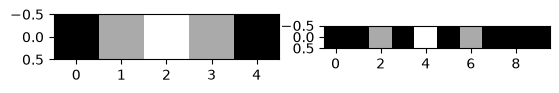

In [6]:
plt.subplot(1,2,1); plt.imshow(f, cmap="gray")
plt.subplot(1,2,2); plt.imshow(g, cmap="gray")

### 동차 행렬을 이용하여, 역방향 사상 구현하기

In [7]:
g = np.zeros((int(h*sx), int(w*sy)))
gh,gw = g.shape
for x_prime in range(gh):
    for y_prime in range(gw):
        P_prime = np.array([[x_prime], [y_prime], [1]])
        P = (np.linalg.inv(A)@P_prime).astype("int16")

        if (0 <= P[0,0] < h) and (0 <= P[1,0] < w):
            g[x_prime,y_prime] = f[P[0,0],P[1,0]] 

g = g.astype("uint8")
print(g)

[[  0   0 120 120 180 180 120 120   0   0]]


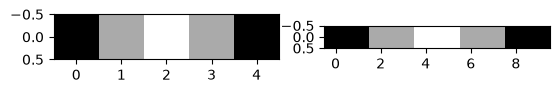

In [8]:
plt.subplot(1,2,1); plt.imshow(f, cmap="gray")
plt.subplot(1,2,2); plt.imshow(g, cmap="gray")